# KNN

In [1]:
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt


In [2]:
train_X = pd.read_csv('data/cleaned/X_train_scaled.csv', index_col=0)
train_y = pd.read_csv('data/cleaned/y_train.csv', index_col=0)['Target']
val_X = pd.read_csv('data/cleaned/X_val_scaled.csv', index_col=0)
val_y = pd.read_csv('data/cleaned/y_val.csv', index_col=0)['Target']

assert train_X.columns.equals(val_X.columns), 'Fitur train dan validation tidak cocok. Jalankan ulang preprocessing.'
assert train_X.index.equals(train_y.index), 'Jumlah/urutan fitur dan label train tidak cocok. Jalankan ulang preprocessing.'
assert val_X.index.equals(val_y.index), 'Jumlah/urutan fitur dan label validation tidak cocok. Jalankan ulang preprocessing.'
print(f'Train: {len(train_X)} fitur / {len(train_y)} label')
print(f'Validation: {len(val_X)} fitur / {len(val_y)} label')


Train: 2322 fitur / 2322 label
Validation: 774 fitur / 774 label


In [3]:
class KNNClassifier():
    def __init__(self, k):
        self.k = k

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype = np.float32)
        self.y_train = np.asarray(y).ravel()

        self._classes_ , self.y_encoded = np.unique(self.y_train, return_inverse=True)
        return self

    def predict(self, X, distance_metric, batch_size = 64):
        X = np.asarray(X, dtype = np.float32)

        if distance_metric not in ['euclidean', 'manhattan']:
            raise ValueError("Invalid distance metric. Choose 'euclidean' or 'manhattan'.")

        Y_pred = np.empty(len(X), dtype=self._classes_.dtype)
        for start in range(0, len(X), batch_size):
            batch = X[start:start + batch_size]
            #shape : (batch_size, jumlah_data_train, jumlah_fitur)
            differences = batch[:, np.newaxis, :] - self.X_train[np.newaxis, :, :]
            #cek distance metric
            if distance_metric == 'euclidean':
                distances = np.sqrt(np.sum(differences ** 2, axis=2))
            elif distance_metric == 'manhattan':
                distances = np.sum(np.abs(differences), axis=2)
            #ambil k tetangga terdekat
            nearest_indices = np.argsort(distances, axis=1)[:, :self.k]
            #ambil label dari tetangga terdekat 
            nearest_labels = self.y_encoded[nearest_indices]
            #hitung jumlah suara untuk setiap kelas
            votes = (
                nearest_labels[:, :, np.newaxis]
                == np.arange(len(self._classes_))[None, None, :]
            ).sum(axis=1)
            #ambil kelas dengan jumlah suara terbanyak
            winners = np.argmax(votes, axis=1)
            #set predicted labels untuk batch saat ini
            Y_pred[start:start + batch_size] = self._classes_[winners]

        return Y_pred

## Mencari best K menggunakan elbow method

K terbaik berdasarkan validation error minimum:
            k  validation_accuracy  validation_error
metric                                              
manhattan  15             0.741602          0.258398
euclidean  15             0.732558          0.267442


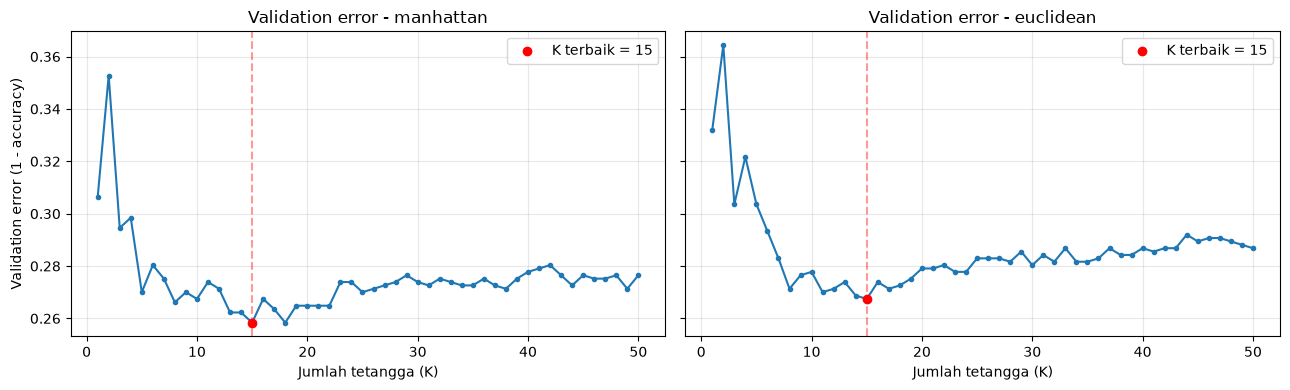

In [4]:
metric = ['manhattan', 'euclidean']
k_values = range(1, min(50, len(train_X)) + 1)
results = []

search_model = KNNClassifier(k=1).fit(train_X.values, train_y.to_numpy())
for m in metric:
    for candidate_k in k_values:
        search_model.k = candidate_k
        predictions = search_model.predict(val_X.values, m)
        accuracy = accuracy_score(val_y, predictions)
        results.append({
            'metric': m,
            'k': candidate_k,
            'validation_accuracy': accuracy,
            'validation_error': 1 - accuracy,
        })

k_results = pd.DataFrame(results)
best_results = (
    k_results.sort_values(['validation_error', 'k'])
    .groupby('metric', sort=False).head(1)
    .set_index('metric').loc[metric]
)
best_k_by_metric = best_results['k'].astype(int).to_dict()
print('K terbaik berdasarkan validation error minimum:')
print(best_results.to_string())

fig, axes = plt.subplots(1, len(metric), figsize=(13, 4), sharey=True)
for ax, m in zip(axes, metric):
    scores = k_results[k_results['metric'] == m]
    best = best_results.loc[m]
    ax.plot(scores['k'], scores['validation_error'], marker='o', markersize=3)
    ax.scatter(best['k'], best['validation_error'], color='red', zorder=3,
               label=f"K terbaik = {int(best['k'])}")
    ax.axvline(best['k'], color='red', linestyle='--', alpha=0.4)
    ax.set(title=f'Validation error - {m}', xlabel='Jumlah tetangga (K)')
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel('Validation error (1 - accuracy)')
plt.tight_layout()
plt.show()


In [5]:
models_diy = {}
for m in metric:
    k = best_k_by_metric[m]
    model_diy = KNNClassifier(k).fit(train_X.values, train_y.to_numpy())
    models_diy[m] = model_diy
    model_lib = KNeighborsClassifier(n_neighbors=k, metric=m)
    model_lib.fit(train_X.values, train_y.to_numpy())

    pred_diy = model_diy.predict(val_X.values, m)
    pred_lib = model_lib.predict(val_X.values)

    print(f"Accuracy on validation set our model [{m}, K={k}]:", accuracy_score(val_y, pred_diy) * 100)
    print(f"Accuracy on validation set sklearn model [{m}, K={k}]:", accuracy_score(val_y, pred_lib) * 100)


Accuracy on validation set our model [manhattan, K=15]: 74.16020671834626
Accuracy on validation set sklearn model [manhattan, K=15]: 74.16020671834626
Accuracy on validation set our model [euclidean, K=15]: 73.25581395348837
Accuracy on validation set sklearn model [euclidean, K=15]: 73.25581395348837


In [6]:
# Student_ID adalah kolom ID asli; jangan jadikan kolom pertama sebagai index.
test_df = pd.read_csv('data/cleaned/test_df.csv')
student_ids = test_df['Student_ID'].to_numpy()

sample_submission = pd.read_csv('data/sample_submission.csv')

test_X = test_df.loc[:, train_X.columns]
target_mapping = {0: 'Dropout', 1: 'Enrolled', 2: 'Graduate'}

def decode_targets(predictions):
    labels = pd.Series(predictions).replace(target_mapping)
    if not labels.isin(target_mapping.values()).all():
        raise ValueError('Unknown target label in predictions.')
    return labels.to_numpy()

for m in metric:
    k = best_k_by_metric[m]
    model_diy = models_diy[m]
    # model_lib = KNeighborsClassifier(n_neighbors=k, metric=m)
    # model_lib.fit(train_X.values, train_y.to_numpy())

    pred_diy = model_diy.predict(test_X.values, m)
    # pred_lib = model_lib.predict(test_X.values)

    submission_diy = pd.DataFrame({'Student_ID': student_ids, 'Target': decode_targets(pred_diy)})
    # submission_lib = pd.DataFrame({'Student_ID': student_ids, 'Target': decode_targets(pred_lib)})

    submission_diy.to_csv(f'../output/csv/submission_knn_{m}.csv', index=False)
    # submission_lib.to_csv(f'../output/csv/submission_knn_lib_{m}.csv', index=False)


In [8]:
import joblib

best_metric = best_results['validation_error'].idxmin()
model_diy = models_diy[best_metric]
joblib.dump(model_diy, '../output/knn_model_diy.pkl')
joblib.dump(
    {'metric': best_metric, 'k': best_k_by_metric[best_metric]},
    '../output/knn_model_diy_config.pkl',
)
print(f'Model tersimpan: metric={best_metric}, K={model_diy.k}')


Model tersimpan: metric=manhattan, K=15
